## Implementation of Linear regression using python

In [1]:
### import required libraries
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score
import matplotlib.pyplot as plt

## Load the dataset

In [2]:
DF1 = pd.read_csv("weight-height.csv")
DF1.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


### Standardize numerical features

In [3]:
col=["Height","Weight"]
S1=MinMaxScaler()
DF1[col]=S1.fit_transform(DF1[col])
DF1.head()

,Gender,Height,Weight
0,Male,0.165212,0.863139
1,Male,0.122482,0.475476
2,Male,0.167432,0.721131
3,Male,0.147361,0.756699
4,Male,0.131761,0.689999


## Prepare dependant and independant variables

In [4]:
X=DF1[["Height"]].to_numpy()
Y=DF1[["Weight"]].to_numpy()
print(X.shape)
print(Y.shape)

(10000, 1)
(10000, 1)


## Split the data into training and test set

In [5]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=.2,random_state=67)

In [6]:
# Create a linear regression model
model=LinearRegression()

Note: Learning more about Linear Regression model here: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 



In [7]:
## Training  Linear regressions model 

In [8]:
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[3.55]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.11]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[3.28]


In [9]:
## Calculating the Mean Squared Error (MSE) and R-squared (R2)
Y_pred=model.predict(X_test)
mse=mean_squared_error(Y_test,Y_pred)
rmse = mean_squared_error(Y_test, Y_pred) ** 0.5
mae = mean_absolute_error(Y_test, Y_pred)
r2=r2_score(Y_test,Y_pred)
print(mse)
print(rmse)
print(mae)
print(r2)

# Print model coefficients
print(model.coef_[0])
print(model.intercept_)

0.0044380478890117024
0.06661867522708405
0.054480150433493836
0.8135299373473699
[3.54709605]
[0.10829265]


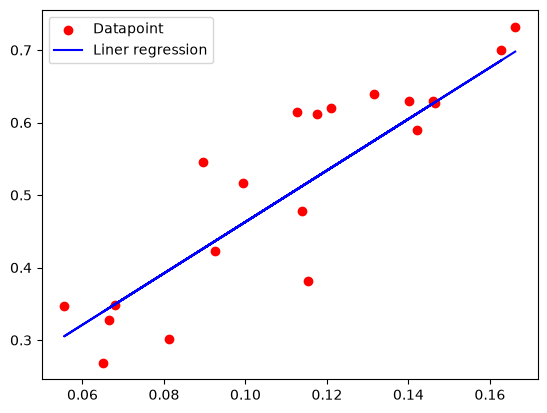

In [10]:
# Plot the linear regression Model 
plt.scatter(X_test[0:20],Y_test[0:20],color="Red",label="Datapoint")
plt.plot(X_test[0:20],Y_pred[0:20],color="Blue",label="Liner regression")
plt.legend()

In [11]:
## Load the Height and weight to independent and dependent variable 

In [12]:
DF2 = pd.read_csv("weight-height.csv")
X = DF2["Height"].values.reshape(-1,1)
X.shape
Y = DF2["Weight"].values
print(X.shape)
print(Y.shape)

(10000, 1)
(10000,)


### Z-Score Normalization

The Z-score normalization formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- $x$ = Original data value
- $\mu$ = Mean of the dataset
- $\sigma$ = Standard deviation of the dataset
- $z$ = Normalized Z-score

In [13]:
## Standardizes the features X and target variable y using Z-score normalization (also called Standardization). 
X = (X - np.mean(X, axis=0)) / np.std(X, axis=0)
Y = (Y - np.mean(Y, axis=0)) / np.std(Y, axis=0)

[![Single-Input-Linear-Neuron-Diagram.png](https://i.postimg.cc/PxYWMz4F/Single-Input-Linear-Neuron-Diagram.png)](https://postimg.cc/vg8xYnCW)

In [14]:
#add another feature to X corresponding to bias
X = np.hstack((np.ones((X.shape[0], 1)), X))
X

array([[ 1.        ,  1.75827913],
       [ 1.        ,  0.56277158],
       [ 1.        ,  1.82037531],
       ...,
       [ 1.        , -0.59704831],
       [ 1.        , 24.22511229],
       [ 1.        , -1.05110595]], shape=(10000, 2))

In [15]:
#weight or parameter initialization
theta = np.zeros(X.shape[1])
iterations=2000
# Hyperparameters
learningrate=0.01
# Gradient Descent
mseh=[] #mse history
print(X.shape)
m=X.T
print(m.shape)

(10000, 2)
(2, 10000)


<img src="https://i.postimg.cc/wMYVXD65/1.png" alt="Image Description" width="500">

In [16]:
for i in range(iterations):
	y_pred = np.dot(X,theta)
	mse = mean_squared_error(Y,y_pred)
	mseh.append(mse)
	print(f"Iteration {i+1}: MSE = {mse}")
	gradient = np.dot(X.T, (y_pred - Y)) / len(Y)
	theta -= learningrate * gradient

Iteration 1: MSE = 1.0
Iteration 2: MSE = 0.985809419277575
Iteration 3: MSE = 0.9719012311115264
Iteration 4: MSE = 0.9582698158899818
Iteration 5: MSE = 0.9449096658313463
Iteration 6: MSE = 0.9318153827588774
Iteration 7: MSE = 0.9189816759195508
Iteration 8: MSE = 0.9064033598463267
Iteration 9: MSE = 0.8940753522629599
Iteration 10: MSE = 0.8819926720305018
Iteration 11: MSE = 0.87015043713467
Iteration 12: MSE = 0.8585438627132649
Iteration 13: MSE = 0.847168259122846
Iteration 14: MSE = 0.8360190300438766
Iteration 15: MSE = 0.8250916706235781
Iteration 16: MSE = 0.8143817656557442
Iteration 17: MSE = 0.8038849877967698
Iteration 18: MSE = 0.7935970958171891
Iteration 19: MSE = 0.7835139328880019
Iteration 20: MSE = 0.7736314249011057
Iteration 21: MSE = 0.7639455788231487
Iteration 22: MSE = 0.7544524810821431
Iteration 23: MSE = 0.7451482959861835
Iteration 24: MSE = 0.7360292641736333
Iteration 25: MSE = 0.727091701094153
Iteration 26: MSE = 0.7183319955199544
Iteration 27: M

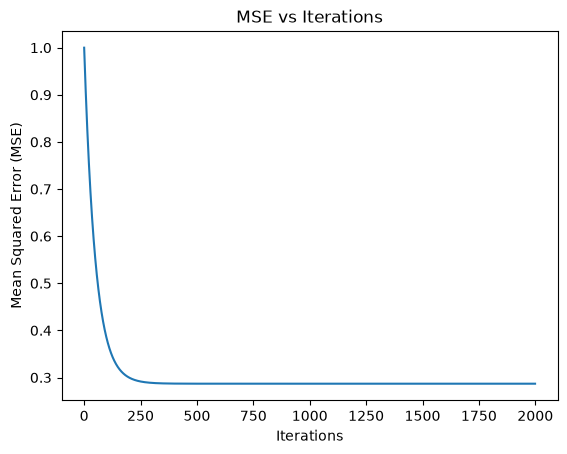

In [17]:
# Plot the MSE over iterations
plt.plot(range(iterations), mseh)
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE vs Iterations')
plt.show()

In [18]:
print(theta)

[1.32399913e-15 8.44449232e-01]


## You are required to fit a linear function on Food_delivery_times dataset
Description about the dataset: This dataset is designed for predicting food delivery times based on various influencing factors such as distance, weather, traffic conditions, and Preperation time. 
1. Feature selection: Consider Food_delivery_time is effected by four features (attributes) given in the dataset, which are Distance_km, Preparation_Time_min, Traffic, Weather
2. Since Traffic, Weather are having categorical values, you need to convert them into numerical using the categorical encoding methods.
3. Now, fit a linear regression model considering Distance_km, Preparation_Time_min, Traffic, and Weather as independant variables and Delivery_Time_min as dependant varibal. 


Note: In lab record, you can write the statements relevant to linear regression.

## Linear Regression on the Food Delivery Times Dataset

The following section follows the lab instructions using `Distance_km`, `Preparation_Time_min`, `Traffic_Level`, and `Weather` as independent variables, with `Delivery_Time_min` as the dependent variable.

The categorical columns are encoded, missing values are handled, and the preprocessing steps are fitted on the training data only.

In [19]:
# Import only the additional preprocessing tools needed for this dataset
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

### Load the food delivery dataset

In [20]:
DF_food = pd.read_csv("Food_Delivery_Times.csv")
display(DF_food.head())

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


### Inspect the dataset

In [21]:
# Check the dataset dimensions and column types
print("Dataset shape:", DF_food.shape)
print("\nColumn information:")
print(DF_food.dtypes)

# Check missing values in each column
print("\nMissing values:")
print(DF_food.isnull().sum())

# Display summary statistics for numerical and categorical columns
display(DF_food.describe(include='all'))

Dataset shape: (1000, 9)

Column information:
Order_ID                    int64
Distance_km               float64
Weather                       str
Traffic_Level                 str
Time_of_Day                   str
Vehicle_Type                  str
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

Missing values:
Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,970,970,970,1000,1000.000000,970.000000,1000.000000
unique,NaN,NaN,5,3,4,3,NaN,NaN,NaN
top,NaN,NaN,Clear,Medium,Morning,Bike,NaN,NaN,NaN
freq,NaN,NaN,470,390,308,503,NaN,NaN,NaN
mean,500.500000,10.059970,NaN,NaN,NaN,NaN,16.982000,4.579381,56.732000
std,288.819436,5.696656,NaN,NaN,NaN,NaN,7.204553,2.914394,22.070915
min,1.000000,0.590000,NaN,NaN,NaN,NaN,5.000000,0.000000,8.000000
25%,250.750000,5.105000,NaN,NaN,NaN,NaN,11.000000,2.000000,41.000000
50%,500.500000,10.190000,NaN,NaN,NaN,NaN,17.000000,5.000000,55.500000
75%,750.250000,15.017500,NaN,NaN,NaN,NaN,23.000000,7.000000,71.000000


### Select the independent and dependent variables

In [22]:
# Select the four independent variables
X_food = DF_food[[
    "Distance_km",
    "Preparation_Time_min",
    "Traffic_Level",
    "Weather"
]]

# Select the dependent variable
Y_food = DF_food["Delivery_Time_min"]

# Display the dimensions to verify the selection
print("Shape of X:", X_food.shape)
print("Shape of Y:", Y_food.shape)

display(X_food.head())
display(Y_food.head())

Shape of X: (1000, 4)
Shape of Y: (1000,)


,Distance_km,Preparation_Time_min,Traffic_Level,Weather
0,7.93,12,Low,Windy
1,16.42,20,Medium,Clear
2,9.52,28,Low,Foggy
3,7.44,5,Medium,Rainy
4,19.03,16,Low,Clear


0    43
1    84
2    59
3    37
4    68
Name: Delivery_Time_min, dtype: int64

### Split the data into training and test sets

In [23]:
# Use 80% of the rows for training and 20% for testing
X_food_train, X_food_test, Y_food_train, Y_food_test = train_test_split(
    X_food,
    Y_food,
    test_size=0.2,
    random_state=67
)

# Display the resulting shapes
print("X_train shape:", X_food_train.shape)
print("X_test shape:", X_food_test.shape)
print("Y_train shape:", Y_food_train.shape)
print("Y_test shape:", Y_food_test.shape)

X_train shape: (800, 4)
X_test shape: (200, 4)
Y_train shape: (800,)
Y_test shape: (200,)


### Encode categorical variables and scale numerical variables

In [24]:
# Identify numerical and categorical columns
numeric_features_food = ["Distance_km", "Preparation_Time_min"]
categorical_features_food = ["Traffic_Level", "Weather"]

# Numerical preprocessing: fill missing values with the training median,
# then scale numerical features to the range [0, 1].
numeric_transformer_food = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler())
])

# Categorical preprocessing: fill missing values with the most frequent
# training category, then one-hot encode the categories.
categorical_transformer_food = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column group
preprocessor_food = ColumnTransformer(transformers=[
    ("num", numeric_transformer_food, numeric_features_food),
    ("cat", categorical_transformer_food, categorical_features_food)
])

# Fit preprocessing on training data only, then transform both sets
X_food_train_processed = preprocessor_food.fit_transform(X_food_train)
X_food_test_processed = preprocessor_food.transform(X_food_test)

print("Processed training shape:", X_food_train_processed.shape)
print("Processed testing shape:", X_food_test_processed.shape)

Processed training shape: (800, 8)
Processed testing shape: (200, 8)


### Create and train the linear regression model

In [25]:
# Create the linear regression model
model_food = LinearRegression()

# Train the model on the preprocessed training data
model_food.fit(X_food_train_processed, Y_food_train)

print("Food delivery linear regression model trained successfully.")

Food delivery linear regression model trained successfully.


### Predict delivery times

In [26]:
# Predict delivery times for the test data
Y_food_pred = model_food.predict(X_food_test_processed)

# Compare the actual and predicted values for the first ten test rows
food_results = pd.DataFrame({
    "Actual Delivery Time": Y_food_test.to_numpy(),
    "Predicted Delivery Time": Y_food_pred
})

display(food_results.head(10))

,Actual Delivery Time,Predicted Delivery Time
0,57,56.001536
1,67,57.750301
2,68,73.343011
3,28,33.090371
4,42,39.644224
5,47,49.742772
6,54,49.000784
7,28,32.095307
8,60,51.425882
9,68,82.929859


### Evaluate the scikit-learn model

In [27]:
# Calculate regression evaluation metrics on the held-out test set
mse_food = mean_squared_error(Y_food_test, Y_food_pred)
rmse_food = np.sqrt(mse_food)
mae_food = mean_absolute_error(Y_food_test, Y_food_pred)
r2_food = r2_score(Y_food_test, Y_food_pred)

print("Mean Squared Error (MSE):", mse_food)
print("Root Mean Squared Error (RMSE):", rmse_food)
print("Mean Absolute Error (MAE):", mae_food)
print("R-squared (R2):", r2_food)

# Display the learned intercept
print("\nModel intercept:", model_food.intercept_)

Mean Squared Error (MSE): 91.38751285499865
Root Mean Squared Error (RMSE): 9.559681629374413
Mean Absolute Error (MAE): 6.540848788357169
R-squared (R2): 0.8232476685812321

Model intercept: 21.944036831549624


### Display the learned feature coefficients

In [28]:
# Retrieve the names of the features after preprocessing
food_feature_names = preprocessor_food.get_feature_names_out()

# Pair each transformed feature with its learned coefficient
food_coefficients = pd.DataFrame({
    "Feature": food_feature_names,
    "Coefficient": model_food.coef_
})

display(food_coefficients)

,Feature,Coefficient
0,num__Distance_km,57.014311
1,num__Preparation_Time_min,23.168080
2,cat__Traffic_Level_Low,-12.255669
3,cat__Traffic_Level_Medium,-6.550580
4,cat__Weather_Foggy,8.277228
5,cat__Weather_Rainy,4.737342
6,cat__Weather_Snowy,9.405060
7,cat__Weather_Windy,1.023424


### Plot actual versus predicted delivery times

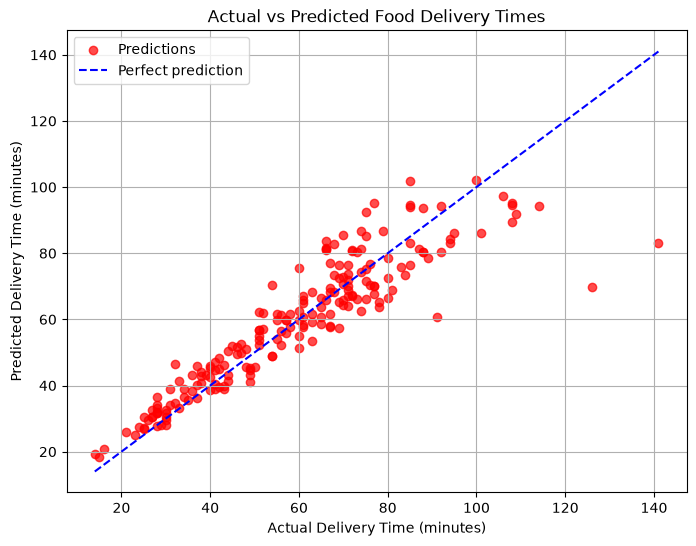

In [29]:
# Compare the model's predictions with the actual test values
plt.figure(figsize=(8, 6))
plt.scatter(
    Y_food_test,
    Y_food_pred,
    color="red",
    alpha=0.7,
    label="Predictions"
)

# The diagonal line represents perfect predictions
min_food_value = min(Y_food_test.min(), Y_food_pred.min())
max_food_value = max(Y_food_test.max(), Y_food_pred.max())
plt.plot(
    [min_food_value, max_food_value],
    [min_food_value, max_food_value],
    color="blue",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Food Delivery Times")
plt.legend()
plt.grid(True)
plt.show()

## Manual Linear Regression Using Gradient Descent

This section implements linear regression manually. The same four features are used. Categorical features are one-hot encoded, missing values are imputed, and Z-score normalization statistics are learned from the training set.

### Split the data for manual gradient descent

In [30]:
# Select the same independent variables and target
X_food_manual = DF_food[[
    "Distance_km",
    "Preparation_Time_min",
    "Traffic_Level",
    "Weather"
]].copy()
Y_food_manual = DF_food["Delivery_Time_min"].copy()

# Use the same reproducible 80:20 train-test split
X_food_train_m, X_food_test_m, Y_food_train_m, Y_food_test_m = train_test_split(
    X_food_manual,
    Y_food_manual,
    test_size=0.2,
    random_state=67
)

print("Training data shape:", X_food_train_m.shape)
print("Testing data shape:", X_food_test_m.shape)

Training data shape: (800, 4)
Testing data shape: (200, 4)


### Handle missing values

In [31]:
# Work with copies of the split datasets
X_food_train_m = X_food_train_m.copy()
X_food_test_m = X_food_test_m.copy()

# Fill missing numerical values using medians calculated from training data
numeric_cols_food = ["Distance_km", "Preparation_Time_min"]
for col in numeric_cols_food:
    median_value = X_food_train_m[col].median()
    X_food_train_m[col] = X_food_train_m[col].fillna(median_value)
    X_food_test_m[col] = X_food_test_m[col].fillna(median_value)

# Fill missing categorical values using modes calculated from training data
categorical_cols_food = ["Traffic_Level", "Weather"]
for col in categorical_cols_food:
    mode_value = X_food_train_m[col].mode()[0]
    X_food_train_m[col] = X_food_train_m[col].fillna(mode_value)
    X_food_test_m[col] = X_food_test_m[col].fillna(mode_value)

print("Remaining missing values in training data:", X_food_train_m.isnull().sum().sum())
print("Remaining missing values in testing data:", X_food_test_m.isnull().sum().sum())

Remaining missing values in training data: 0
Remaining missing values in testing data: 0


### Convert categorical features into numerical columns

In [32]:
# One-hot encode categorical columns in the training and test sets
X_food_train_m = pd.get_dummies(
    X_food_train_m,
    columns=categorical_cols_food,
    drop_first=True,
    dtype=float
)

X_food_test_m = pd.get_dummies(
    X_food_test_m,
    columns=categorical_cols_food,
    drop_first=True,
    dtype=float
)

# Match test columns to the training columns and preserve their order
X_food_test_m = X_food_test_m.reindex(
    columns=X_food_train_m.columns,
    fill_value=0
)

print("Encoded training shape:", X_food_train_m.shape)
print("Encoded testing shape:", X_food_test_m.shape)
display(X_food_train_m.head())

Encoded training shape: (800, 8)
Encoded testing shape: (200, 8)


,Distance_km,Preparation_Time_min,Traffic_Level_Low,Traffic_Level_Medium,Weather_Foggy,Weather_Rainy,Weather_Snowy,Weather_Windy
455,2.59,13,0.0,1.0,0.0,0.0,0.0,1.0
903,2.14,25,1.0,0.0,0.0,0.0,0.0,0.0
651,4.50,20,1.0,0.0,0.0,0.0,0.0,1.0
513,4.08,7,0.0,1.0,0.0,0.0,0.0,1.0
645,19.28,21,0.0,1.0,0.0,0.0,1.0,0.0


### Apply Z-score normalization

In [33]:
# Convert the encoded feature tables to NumPy arrays
X_food_train_array = X_food_train_m.to_numpy(dtype=float)
X_food_test_array = X_food_test_m.to_numpy(dtype=float)

# Learn the feature means and standard deviations from training data only
X_food_mean = X_food_train_array.mean(axis=0)
X_food_std = X_food_train_array.std(axis=0)
X_food_std[X_food_std == 0] = 1  # Avoid division by zero for constant columns

# Standardize training and test features using the same statistics
X_food_train_scaled = (X_food_train_array - X_food_mean) / X_food_std
X_food_test_scaled = (X_food_test_array - X_food_mean) / X_food_std

# Standardize the target using training-set statistics
Y_food_mean = Y_food_train_m.mean()
Y_food_std = Y_food_train_m.to_numpy(dtype=float).std(ddof=0)
Y_food_train_scaled = (
    Y_food_train_m.to_numpy(dtype=float) - Y_food_mean
) / Y_food_std

print("X training shape:", X_food_train_scaled.shape)
print("X testing shape:", X_food_test_scaled.shape)
print("Y training shape:", Y_food_train_scaled.shape)

X training shape: (800, 8)
X testing shape: (200, 8)
Y training shape: (800,)


### Add the bias column

In [34]:
# Add a column of ones so the first parameter represents the bias/intercept
X_food_train_bias = np.hstack((
    np.ones((X_food_train_scaled.shape[0], 1)),
    X_food_train_scaled
))

X_food_test_bias = np.hstack((
    np.ones((X_food_test_scaled.shape[0], 1)),
    X_food_test_scaled
))

print("Training matrix shape:", X_food_train_bias.shape)
print("Testing matrix shape:", X_food_test_bias.shape)

Training matrix shape: (800, 9)
Testing matrix shape: (200, 9)


### Initialize parameters and hyperparameters

In [35]:
# Initialize one parameter for the bias and one for every processed feature
theta_food = np.zeros(X_food_train_bias.shape[1])

# Set gradient descent hyperparameters
iterations_food = 2000
learningrate_food = 0.01

# Store the MSE at each iteration
mseh_food = []

print("Number of parameters:", len(theta_food))
print("Initial parameters:", theta_food)

Number of parameters: 9
Initial parameters: [0. 0. 0. 0. 0. 0. 0. 0. 0.]


### Train using gradient descent

In [36]:
# Train the model by repeatedly updating the parameters
m_food = len(Y_food_train_scaled)

for i in range(iterations_food):
    # Predict standardized delivery times
    Y_food_pred_scaled = np.dot(X_food_train_bias, theta_food)

    # Calculate and store the current mean squared error
    mse_iteration_food = np.mean((Y_food_pred_scaled - Y_food_train_scaled) ** 2)
    mseh_food.append(mse_iteration_food)

    # Calculate the gradient of the mean squared error
    gradient_food = (2 / m_food) * np.dot(
        X_food_train_bias.T,
        Y_food_pred_scaled - Y_food_train_scaled
    )

    # Update the parameters in the direction that reduces the error
    theta_food -= learningrate_food * gradient_food

    # Print progress every 100 iterations
    if (i + 1) % 100 == 0:
        print(f"Iteration {i + 1}: MSE = {mse_iteration_food:.6f}")

print("\nGradient descent training completed.")
print("Final parameters:", theta_food)

Iteration 100: MSE = 0.270987
Iteration 200: MSE = 0.251503
Iteration 300: MSE = 0.249802
Iteration 400: MSE = 0.249420
Iteration 500: MSE = 0.249317
Iteration 600: MSE = 0.249289
Iteration 700: MSE = 0.249281
Iteration 800: MSE = 0.249279
Iteration 900: MSE = 0.249278
Iteration 1000: MSE = 0.249278
Iteration 1100: MSE = 0.249278
Iteration 1200: MSE = 0.249278
Iteration 1300: MSE = 0.249278
Iteration 1400: MSE = 0.249278
Iteration 1500: MSE = 0.249278
Iteration 1600: MSE = 0.249278
Iteration 1700: MSE = 0.249278
Iteration 1800: MSE = 0.249278
Iteration 1900: MSE = 0.249278
Iteration 2000: MSE = 0.249278

Gradient descent training completed.
Final parameters: [ 6.28386232e-18  7.63046921e-01  3.17444661e-01 -2.70709464e-01
 -1.48912065e-01  1.17977726e-01  8.52988758e-02  1.28455705e-01
  1.33247855e-02]


### Plot MSE versus iterations

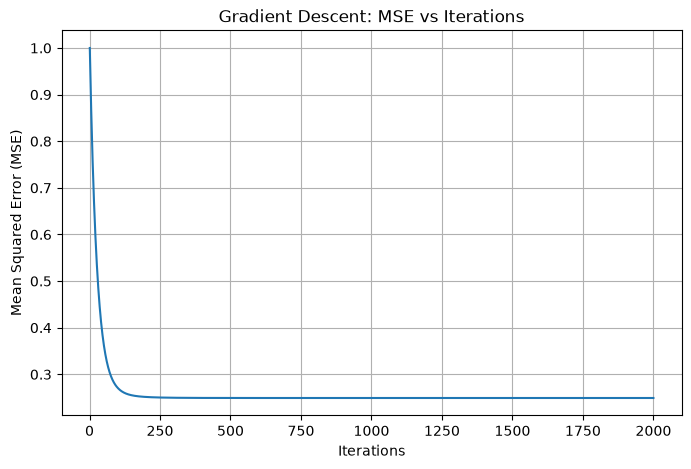

In [37]:
# Plot the MSE history recorded during gradient descent
plt.figure(figsize=(8, 5))
plt.plot(range(1, iterations_food + 1), mseh_food)
plt.xlabel("Iterations")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Gradient Descent: MSE vs Iterations")
plt.grid(True)
plt.show()

### Predict on the test set and reverse normalization

In [38]:
# Predict standardized delivery times for the test data
Y_food_pred_test_scaled = np.dot(X_food_test_bias, theta_food)

# Convert predictions back to minutes
Y_food_pred_manual = (Y_food_pred_test_scaled * Y_food_std) + Y_food_mean

# Compare actual and predicted values
food_manual_results = pd.DataFrame({
    "Actual Delivery Time": Y_food_test_m.to_numpy(),
    "Predicted Delivery Time": Y_food_pred_manual
})

display(food_manual_results.head(10))

,Actual Delivery Time,Predicted Delivery Time
0,57,56.001515
1,67,57.750306
2,68,73.342991
3,28,33.090374
4,42,39.644231
5,47,49.742775
6,54,49.000787
7,28,32.095312
8,60,51.425888
9,68,82.929841


### Evaluate the manual model

In [39]:
# Evaluate predictions on the test set in the original unit (minutes)
mse_food_manual = mean_squared_error(Y_food_test_m, Y_food_pred_manual)
rmse_food_manual = np.sqrt(mse_food_manual)
mae_food_manual = mean_absolute_error(Y_food_test_m, Y_food_pred_manual)
r2_food_manual = r2_score(Y_food_test_m, Y_food_pred_manual)

print("Manual Gradient Descent Results")
print("--------------------------------")
print("MSE:", mse_food_manual)
print("RMSE:", rmse_food_manual)
print("MAE:", mae_food_manual)
print("R-squared:", r2_food_manual)

Manual Gradient Descent Results
--------------------------------
MSE: 91.38749092924732
RMSE: 9.559680482591839
MAE: 6.540847572421246
R-squared: 0.8232477109877661


### Plot actual versus predicted values for manual gradient descent

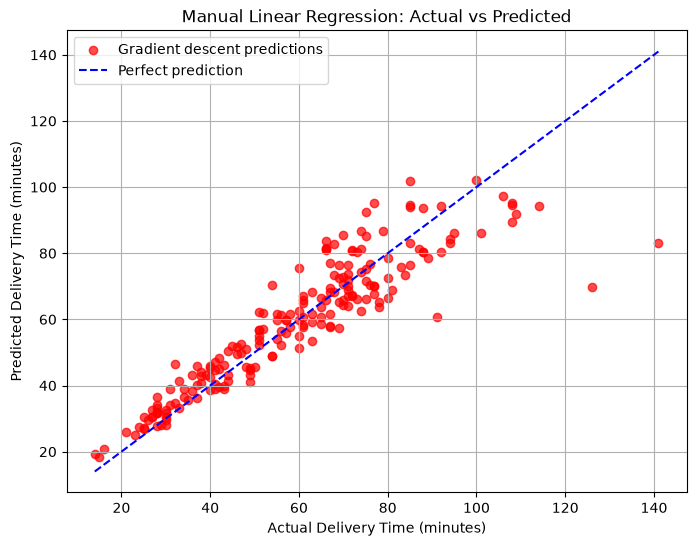

In [40]:
# Compare manual-model predictions with actual test values
plt.figure(figsize=(8, 6))
plt.scatter(
    Y_food_test_m,
    Y_food_pred_manual,
    color="red",
    alpha=0.7,
    label="Gradient descent predictions"
)

# Add the perfect-prediction reference line
min_food_manual = min(Y_food_test_m.min(), Y_food_pred_manual.min())
max_food_manual = max(Y_food_test_m.max(), Y_food_pred_manual.max())
plt.plot(
    [min_food_manual, max_food_manual],
    [min_food_manual, max_food_manual],
    color="blue",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Manual Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

### Compare the two implementations

In [41]:
# Compare scikit-learn linear regression with manual gradient descent
food_model_comparison = pd.DataFrame({
    "Metric": ["MSE", "RMSE", "MAE", "R-squared"],
    "Scikit-learn": [mse_food, rmse_food, mae_food, r2_food],
    "Manual Gradient Descent": [
        mse_food_manual,
        rmse_food_manual,
        mae_food_manual,
        r2_food_manual
    ]
})

display(food_model_comparison)

,Metric,Scikit-learn,Manual Gradient Descent
0,MSE,91.387513,91.387491
1,RMSE,9.559682,9.559680
2,MAE,6.540849,6.540848
3,R-squared,0.823248,0.823248


### Notes for the lab record

- `Traffic_Level` is the actual column name in the CSV; the lab description calls it `Traffic`.
- The four selected independent variables are `Distance_km`, `Preparation_Time_min`, `Traffic_Level`, and `Weather`.
- `Delivery_Time_min` is the dependent variable.
- One-hot encoding converts categorical values into numerical indicator columns.
- The test set is kept separate during preprocessing and model training.
- MSE and RMSE are measured in squared minutes and minutes, respectively; MAE is measured in minutes.
- Small differences between the two models are expected because gradient descent is iterative.

## Conclusion
Thus, linear regression was successfully implemented to predict food delivery times using relevant features such as distance, preparation time, traffic level, and weather conditions. Both the Scikit-learn model and the manually implemented gradient descent model produced nearly identical results, achieving an \(R^2\) score of approximately 0.823. This demonstrates that the models explain about 82.3% of the variation in delivery times and highlights the effectiveness of linear regression for this prediction task.